# RAG Part 1: Experiment 2: per-article cap and clean vs raw

Builds on `rag_part1_expt1.ipynb`, which chunked the **raw** corpus into Strategy A (fixed-size) and Strategy B (structure-aware) and indexed both in ChromaDB with `all-mpnet-base-v2`.

Two experiments:

1. **Per-article result cap (diversity).** In expt 1, Strategy B's top 5 averaged only ~1.6 distinct articles, which is bad for cross-article consistency auditing. Over-fetch `K_FETCH` candidates, then limit how many slots one article can take (optionally with MMR). Runs on the existing **raw** collections; no re-embedding.
2. **Clean vs raw.** Preprocess the raw text (normalise Unicode, strip the site-wide legal disclaimer, drop repeated boilerplate paragraphs, drop the legal page), re-chunk with the **same** chunking code, index into new `_clean` collections, and compare with raw on the same evaluation set and retrieval policies.

**Evaluation set:** 150 FAQ questions (one per article, `random_state=0`). The target is the article the question came from. Metrics are article-level: `doc_hit@1`, `doc_hit@5`, `MRR`; plus diversity (`unique_docs@5`, `gold_doc_slots@5`) and boilerplate share among the top 5 (`noise@5`). These questions come from the corpus itself, so absolute scores are optimistic; use them for **relative** comparisons.

## Setup

In [1]:
import os

os.environ.setdefault("HF_HUB_OFFLINE", "1")  # model is cached; skip the Hub check
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")

import re
import unicodedata
from collections import Counter

import chromadb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sentence_transformers import SentenceTransformer

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

/Users/zhaoweikennethlim/Desktop/fin-audit-guard-rag/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1030 11:08:07.351000 45999 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [2]:
EMBEDDING_MODEL = "sentence-transformers/all-mpnet-base-v2"  # same model as expt 1
TARGET_MAX_TOKENS = 350
HEADER_RESERVE = 64
OVERLAP_TOKENS = 50
MIN_SECTION_TOKENS = 50

DATA_DIR = "../data/processed"
CHROMA_PATH = "../.chroma"
EVAL_N, SEED = 150, 0
K = 5  # results handed to the LLM
K_FETCH = 50  # candidates fetched before capping / MMR
EMBED_BATCH = 64

# Boilerplate fingerprints (site footer, author bio, "not advice" notes) used to measure noise in results
NOISE_RE = re.compile(
    r"Legal Disclaimer|BINDING ARBITRATION|INDEMNIFICATION|quantitative research arm of Samuel Jeffery"
    r"|purely for entertainment purposes only|forward-looking statements|Unauthorized commercial reproduction"
)

In [3]:
model = SentenceTransformer(EMBEDDING_MODEL)
tok = model.tokenizer
MAX_SEQ_LENGTH = model.max_seq_length


def n_tokens(text: str) -> int:
    return len(tok(text, add_special_tokens=False, verbose=False)["input_ids"])


MAX_TOKENS = min(TARGET_MAX_TOKENS, MAX_SEQ_LENGTH - HEADER_RESERVE - 2)
OVERLAP_TOKENS = min(OVERLAP_TOKENS, MAX_TOKENS // 4)
MODEL_SLUG = EMBEDDING_MODEL.split("/")[-1]
print(f"{EMBEDDING_MODEL} on {model.device}: max_seq_length={MAX_SEQ_LENGTH} -> MAX_TOKENS={MAX_TOKENS}, OVERLAP_TOKENS={OVERLAP_TOKENS}")

Could not reach the Hub (Cannot reach https://huggingface.co/api/models/sentence-transformers/all-mpnet-base-v2: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.). Using cached commit hash for 'sentence-transformers/all-mpnet-base-v2'.


sentence-transformers/all-mpnet-base-v2 on mps:0: max_seq_length=384 -> MAX_TOKENS=318, OVERLAP_TOKENS=50


### Chunking functions (same logic as expt 1)

Copied from `rag_part1_expt1.ipynb` without changes, so raw and clean chunks differ **only** in the input text.

In [4]:
FAQ_HEADING_RE = re.compile(r"^.{0,200}\bFAQs?\b.{0,200}(?<![.!])$")
FAQ_QUESTION_RE = re.compile(r"^.+\?$")
GLUED_QA_RE = re.compile(r"\?(?=[A-Z])")
TERMINAL_PUNCT = tuple(".!?:;,…\"'”’)]")
FAQ_MIN_POSITION = 0.4
SENT_RE = re.compile(r"(?<=[.!?])\s+(?=[A-Z0-9\"“(])")
ENGAGEMENT_RE = re.compile(r"let me know in the comment", re.I)


def is_heading(line: str, max_chars: int = 80, max_words: int = 12) -> bool:
    s = line.strip()
    return (
        0 < len(s) <= max_chars
        and len(s.split()) <= max_words
        and not s.endswith(TERMINAL_PUNCT)
        and not s.lower().startswith(("source:", "http", "www."))
        and not s.startswith(("-", "•", "*"))
    )


def is_question(line: str) -> bool:
    return bool(FAQ_QUESTION_RE.match(line.strip()))


def split_faq(text: str) -> tuple[str, str, str, str]:
    lines = text.split("\n")
    offset, start = 0, None
    for i, line in enumerate(lines):
        if FAQ_HEADING_RE.match(line.strip()) and offset >= FAQ_MIN_POSITION * len(text):
            start = i
        offset += len(line) + 1
    if start is None:
        return text, "", "", ""
    heading = lines[start].strip()
    rest = []
    for line in lines[start + 1:]:
        rest.extend(GLUED_QA_RE.sub("?\n", line).split("\n"))
    q_idx = [i for i, line in enumerate(rest) if is_question(line)]
    if not q_idx:
        return text, "", "", ""
    end = len(rest)
    for j in range(q_idx[-1] + 2, len(rest)):
        if is_heading(rest[j]):
            end = j
            break
    return ("\n".join(lines[:start]).strip(), heading,
            "\n".join(rest[:end]).strip(), "\n".join(rest[end:]).strip())


def split_qa_pairs(faq: str) -> list[tuple[str, str]]:
    pairs, question, answer = [], None, []
    for line in (l.strip() for l in faq.split("\n") if l.strip()):
        if is_question(line):
            if question and answer:
                pairs.append((question, "\n".join(answer)))
            question, answer = line, []
        elif question:
            answer.append(line)
    if question and answer:
        pairs.append((question, "\n".join(answer)))
    return pairs


def split_sections(text: str, default: str = "Introduction") -> list[tuple[str, str]]:
    sections, heading, buf = [], default, []
    for line in text.split("\n"):
        if not line.strip():
            continue
        if is_heading(line):
            if buf:
                sections.append((heading, "\n".join(buf)))
            heading, buf = line.strip(), []
        else:
            buf.append(line.strip())
    if buf:
        sections.append((heading, "\n".join(buf)))
    return sections


def merge_small_sections(sections, min_tokens: int = MIN_SECTION_TOKENS):
    merged, carry = [], None
    for heading, body in sections:
        if carry:
            heading, body = carry[0], f"{carry[1]}\n{heading}\n{body}"
            carry = None
        if n_tokens(body) < min_tokens:
            carry = (heading, body)
        else:
            merged.append((heading, body))
    if carry:
        if merged:
            h, b = merged[-1]
            merged[-1] = (h, f"{b}\n{carry[0]}\n{carry[1]}")
        else:
            merged.append(carry)
    return merged


def hard_split(text: str, max_tokens: int) -> list[str]:
    offs = tok(text, add_special_tokens=False, return_offsets_mapping=True, verbose=False)["offset_mapping"]
    return [text[offs[i][0]:offs[min(i + max_tokens, len(offs)) - 1][1]] for i in range(0, len(offs), max_tokens)]


def to_units(text: str, max_tokens: int) -> list[str]:
    units = []
    for para in text.split("\n"):
        if not para.strip():
            continue
        if n_tokens(para) <= max_tokens:
            units.append(para)
            continue
        for sent in SENT_RE.split(para):
            units.extend([sent] if n_tokens(sent) <= max_tokens else hard_split(sent, max_tokens))
    return units


def window(text: str, max_tokens: int = MAX_TOKENS, overlap: int = OVERLAP_TOKENS) -> list[str]:
    units = to_units(text, max_tokens)
    sizes = [n_tokens(u) for u in units]
    chunks, cur, cur_sizes = [], [], []
    for unit, size in zip(units, sizes):
        if cur and sum(cur_sizes) + size > max_tokens:
            chunks.append("\n".join(cur))
            k = len(cur)
            while k > 0 and sum(cur_sizes[k - 1:]) <= overlap:
                k -= 1
            cur, cur_sizes = cur[k:], cur_sizes[k:]
            if cur and sum(cur_sizes) + size > max_tokens:
                cur, cur_sizes = [], []
        cur.append(unit)
        cur_sizes.append(size)
    if cur:
        chunks.append("\n".join(cur))
    return chunks


def chunk_doc_structured(doc) -> list[dict]:
    body, faq_heading, faq, post = split_faq(doc.text)
    out = []

    def add(section, chunk_type, text, question=""):
        out.append(dict(section=section, chunk_type=chunk_type, question=question, text=text,
                        embed_text=f"{doc.title} › {section}\n{text}"))

    for title, sec in merge_small_sections(split_sections(body)):
        for c in window(sec):
            add(title, "body", c)
    for q, a in split_qa_pairs(faq):
        if ENGAGEMENT_RE.search(a):
            continue
        budget = MAX_TOKENS - n_tokens(q)
        for piece in [a] if n_tokens(a) <= budget else window(a, max_tokens=budget, overlap=0):
            add(faq_heading, "faq", f"{q}\n{piece}", question=q)
    for title, sec in merge_small_sections(split_sections(post, default="Closing")):
        for c in window(sec):
            add(title, "body", c)
    return out


def chunk_doc_fixed(doc, max_tokens: int = MAX_TOKENS, overlap: int = OVERLAP_TOKENS) -> list[dict]:
    text, step = doc.text, max_tokens - overlap
    offs = tok(text, add_special_tokens=False, return_offsets_mapping=True, verbose=False)["offset_mapping"]
    pieces = []
    for start in range(0, len(offs), step):
        end = min(start + max_tokens, len(offs))
        pieces.append(text[offs[start][0]:offs[end - 1][1]])
        if end == len(offs):
            break
    return [dict(section="", chunk_type="window", question="", text=p, embed_text=p) for p in pieces]


def build_chunks(docs: pd.DataFrame, chunk_fn, strategy: str) -> pd.DataFrame:
    rows = []
    for doc in docs.itertuples(index=False):
        for i, c in enumerate(chunk_fn(doc)):
            rows.append({"chunk_id": f"{doc.doc_id}:{strategy}:{i:04d}", "doc_id": doc.doc_id,
                         "title": doc.title, "chunk_index": i, **c})
    out = pd.DataFrame(rows)
    out["n_tokens"] = out["text"].map(n_tokens)
    return out

### Retrieval policies and metrics

- **`fetch`**: stage 1, the bi-encoder (`all-mpnet-base-v2`). One batched Chroma query per collection returns `K_FETCH` candidates per query, with their embeddings (for MMR).
- **`select`**: chooses the final `K` results from an ordered candidate list.
  - `per_doc_cap=None, mmr_lambda=None`: plain top-K (the expt 1 baseline)
  - `per_doc_cap=c`: walk candidates in order and skip any from an article that already has `c` slots
  - `mmr_lambda=λ`: **Maximal Marginal Relevance, a diversity re-ordering, not relevance reranking.** `score(c) = λ·sim(query, c) − (1−λ)·max over chosen s of sim(c, s)`, combined with the cap. It reuses the stage-1 bi-encoder similarities (`sim(query, c) = 1 − distance`; `sim(c, s)` = dot product of the stored, normalised embeddings). It reduces redundancy but never judges relevance better than stage 1. True relevance reranking with a cross-encoder is Experiment 3.
- **`evaluate`**: article-level metrics against the source article of each FAQ question.
  - `doc_hit@1`: share of questions whose source article is the #1 result
  - `doc_hit@5`: share of questions whose source article appears anywhere in the top 5
  - `MRR`: mean of 1/rank of the source article among the articles in the top 5 (0 if missing)
  - `unique_docs@5`: distinct articles in the top 5
  - `gold_doc_slots@5`: how many of the 5 slots the source article takes
  - `noise@5`: share of the top 5 that are boilerplate chunks
  - `src_chunk@1` / `src_chunk@5` (Strategy B only, Experiment 3): whether the exact FAQ chunk the question came from is #1 / in the top 5. This measures chunk-level precision. It's optimistic, because that chunk contains the question text word for word.

In [5]:
def fetch(col, query_embs: np.ndarray, k_fetch: int = K_FETCH, where: dict | None = None) -> list[list[dict]]:
    r = col.query(query_embeddings=query_embs, n_results=k_fetch, where=where,
                  include=["documents", "metadatas", "distances", "embeddings"])
    return [
        [dict(chunk_id=cid, doc_id=m["doc_id"], title=m["title"], section=m["section"], chunk_type=m["chunk_type"],
              question=m["question"], text=t, sim=1 - d, emb=np.asarray(e))
         for cid, t, m, d, e in zip(ids, docs, metas, dists, embs)]
        for ids, docs, metas, dists, embs in zip(r["ids"], r["documents"], r["metadatas"], r["distances"], r["embeddings"])
    ]


def select(cands: list[dict], k: int = K, per_doc_cap: int | None = None, mmr_lambda: float | None = None) -> list[dict]:
    chosen, per_doc, remaining = [], Counter(), list(range(len(cands)))

    def mmr_score(j: int) -> float:
        redundancy = max((float(cands[j]["emb"] @ c["emb"]) for c in chosen), default=0.0)
        return mmr_lambda * cands[j]["sim"] - (1 - mmr_lambda) * redundancy

    while remaining and len(chosen) < k:
        i = remaining[0] if mmr_lambda is None else max(remaining, key=mmr_score)
        remaining.remove(i)
        c = cands[i]
        if per_doc_cap and per_doc[c["doc_id"]] >= per_doc_cap:
            continue
        chosen.append(c)
        per_doc[c["doc_id"]] += 1
    return chosen


def evaluate(results: list[list[dict]], gold_ids: list[str], gold_questions: list[str] | None = None) -> pd.Series:
    rows = []
    for i, (res, gold) in enumerate(zip(results, gold_ids)):
        docs = [c["doc_id"] for c in res]
        ranked = list(dict.fromkeys(docs))
        row = dict(
            hit1=bool(docs) and docs[0] == gold,
            hit5=gold in docs,
            rr=1 / (ranked.index(gold) + 1) if gold in ranked else 0.0,
            uniq=len(ranked),
            gold_slots=docs.count(gold),
            noise=sum(bool(NOISE_RE.search(c["text"])) for c in res) / max(len(res), 1),
            sim=np.mean([c["sim"] for c in res]),
            n=len(res),
        )
        if gold_questions is not None:  # is the exact source FAQ chunk retrieved?
            is_src = [c["doc_id"] == gold and c["question"] == gold_questions[i] for c in res]
            row.update(src1=bool(is_src) and is_src[0], src5=any(is_src))
        rows.append(row)
    d = pd.DataFrame(rows)
    out = {
        "doc_hit@1": d.hit1.mean(), "doc_hit@5": d.hit5.mean(), "MRR": d.rr.mean(),
        "unique_docs@5": d.uniq.mean(), "gold_doc_slots@5": d.gold_slots.mean(),
        "noise@5": d.noise.mean(), "mean_sim@5": d.sim.mean(), "results_returned": d.n.mean(),
    }
    if gold_questions is not None:
        out.update({"src_chunk@1": d.src1.mean(), "src_chunk@5": d.src5.mean()})
    return pd.Series(out).round(3)


POLICIES = {
    "top-5 (baseline)": dict(),
    "cap 3/doc": dict(per_doc_cap=3),
    "cap 2/doc": dict(per_doc_cap=2),
    "cap 1/doc": dict(per_doc_cap=1),
    "MMR λ=0.6 + cap 2": dict(per_doc_cap=2, mmr_lambda=0.6),
}

## Experiment 1: per-article cap on the raw collections

Uses the collections built in expt 1 (`ppp_all-mpnet-base-v2_A` / `_B`), so nothing is re-embedded.

In [6]:
client = chromadb.PersistentClient(path=CHROMA_PATH)
raw_cols = {s: client.get_collection(f"ppp_{MODEL_SLUG}_{s}") for s in ["A", "B"]}
chunks_B_raw = pd.read_csv(f"{DATA_DIR}/chunks_B_structured.csv", keep_default_na=False)
for s, col in raw_cols.items():
    print(f"{col.name}: {col.count():,} chunks | metadata {col.metadata}")

ppp_all-mpnet-base-v2_A: 12,186 chunks | metadata {'strategy': 'A', 'embedding_model': 'sentence-transformers/all-mpnet-base-v2', 'max_tokens': 318}
ppp_all-mpnet-base-v2_B: 21,764 chunks | metadata {'max_tokens': 318, 'strategy': 'B', 'embedding_model': 'sentence-transformers/all-mpnet-base-v2'}


In [7]:
# Evaluation set: one FAQ question per article; the target is that article
eval_set = (chunks_B_raw[chunks_B_raw.chunk_type == "faq"]
            .drop_duplicates("doc_id")
            .sample(EVAL_N, random_state=SEED)[["doc_id", "title", "question"]]
            .reset_index(drop=True))
eval_set["query"] = eval_set.question.str.replace(r"^\s*\d{1,2}[).]\s*", "", regex=True)
gold_ids = eval_set.doc_id.tolist()
query_embs = model.encode(eval_set["query"].tolist(), normalize_embeddings=True, batch_size=EMBED_BATCH)
eval_set.head()

,doc_id,title,question,query
0,9a8772c753e298db47551f28e2cb58aff322a603,How to Be a More Disciplined Investor: Top 10 Tips for Success,1) What does “discipline” mean in investing?,What does “discipline” mean in investing?
1,90779d637201e12e44f03837e70bc1f8082c0b1d,So Trendy Portfolio | Momentum and Trend-Following Investing,What is the So Trendy Portfolio strategy?,What is the So Trendy Portfolio strategy?
2,1a92343c8d803aa06256e5812ca0200e3974ca2f,Dragon Portfolio Review: All-Weather Asset Allocation Strategy,1) What is the Dragon Portfolio in one sentence?,What is the Dragon Portfolio in one sentence?
3,9c65ec59d1b850708d27c7e430c03e507916555b,How to Invest Like Peter Lynch: Growth Investing Success,1) What’s Peter Lynch’s core philosophy in one line?,What’s Peter Lynch’s core philosophy in one line?
4,eb9bac6478f1ba8ab3e6389f6c82bc31b4ebf42b,TUA ETF: Review Of The Strategy Behind Simplify Short Term Treasury Futures Strategy ETF,What is TUA in one sentence?,What is TUA in one sentence?


In [8]:
raw_cands = {s: fetch(col, query_embs) for s, col in raw_cols.items()}
raw_cands["B body-only"] = fetch(raw_cols["B"], query_embs, where={"chunk_type": "body"})

exp1 = pd.DataFrame({
    (s, p): evaluate([select(c, **kw) for c in cands], gold_ids)
    for s, cands in raw_cands.items() for p, kw in POLICIES.items()
}).T
exp1.index.names = ["strategy", "policy"]
exp1

doc_hit@1  doc_hit@5    MRR  unique_docs@5  gold_doc_slots@5  noise@5  mean_sim@5  results_returned
strategy    policy                                                                                                                
A           top-5 (baseline)       0.673      0.833  0.741          2.380             3.080    0.081       0.647             5.000
            cap 3/doc              0.673      0.840  0.743          3.180             2.160    0.073       0.630             5.000
            cap 2/doc              0.673      0.840  0.743          3.713             1.580    0.075       0.615             5.000
            cap 1/doc              0.673      0.853  0.745          5.000             0.853    0.076       0.590             5.000
            MMR λ=0.6 + cap 2      0.673      0.820  0.727          4.300             1.333    0.071       0.587             5.000
B           top-5 (baseline)       0.780      0.847  0.810          1.620             3.700    0.060       0.693             5.000
            cap 3/doc              0.780      0.860  0.817          2.560             2.440    0.055       0.672             4.820
            cap 2/doc              0.780      0.867  0.819          3.040             1.687    0.053       0.659             4.620
            cap 1/doc              0.780      0.893  0.825          4.040             0.893    0.057       0.643             4.040
            MMR λ=0.6 + cap 2      0.780      0.887  0.821          3.567             1.593    0.078       0.644             4.620
B body-only top-5 (baseline)       0.720      0.840  0.773          1.660             3.647    0.101       0.679             5.000
            cap 3/doc              0.720      0.840  0.773          2.640             2.393    0.091       0.654             4.940
            cap 2/doc              0.720      0.860  0.779          3.167             1.660    0.091       0.638             4.853
            cap 1/doc              0.720      0.887  0.785          4.513             0.887    0.091       0.617             4.513
            MMR λ=0.6 + cap 2      0.720      0.860  0.769          3.960             1.507    0.103       0.617             4.853

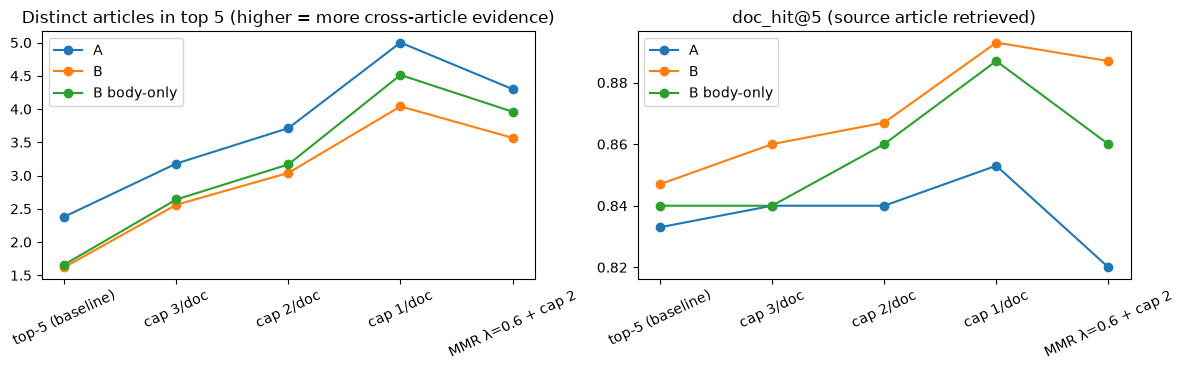

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for s, g in exp1.groupby(level="strategy", sort=False):
    labels = g.index.get_level_values("policy")
    axes[0].plot(labels, g["unique_docs@5"], marker="o", label=s)
    axes[1].plot(labels, g["doc_hit@5"], marker="o", label=s)
axes[0].set_title("Distinct articles in top 5 (higher = more cross-article evidence)")
axes[1].set_title("doc_hit@5 (source article retrieved)")
for ax in axes:
    ax.tick_params(axis="x", rotation=25)
    ax.legend()
plt.tight_layout()
plt.show()

In [10]:
DEMO_QUERIES = [
    "What is the classic Ray Dalio All Weather portfolio allocation?",
    "What is the expense ratio of GDE?",
    "How do managed futures perform in bear markets?",
]
demo_embs = model.encode(DEMO_QUERIES, normalize_embeddings=True)


def show(col, policy: dict, label: str, where: dict | None = None) -> pd.DataFrame:
    rows = []
    for q, cands in zip(DEMO_QUERIES, fetch(col, demo_embs, where=where)):
        for rank, c in enumerate(select(cands, **policy), 1):
            rows.append(dict(query=q[:40], setup=label, rank=rank, sim=round(c["sim"], 3), title=c["title"][:45],
                             section=c["section"][:30], chunk_type=c["chunk_type"], text=c["text"][:110].replace("\n", " ")))
    return pd.DataFrame(rows)


demo_exp1 = pd.concat([show(raw_cols["B"], {}, "B raw top-5"), show(raw_cols["B"], {"per_doc_cap": 2}, "B raw cap 2")])
demo_exp1

,query,setup,rank,sim,title,section,chunk_type,text
0,What is the classic Ray Dalio All Weathe,B raw top-5,1,0.846,10 Ways Investors Can Improve The Ray Dalio A,12-Question FAQ — 10 Ways Inve,faq,1) What is the classic Ray Dalio All Weather Portfolio? A rules-driven allocation aimed to work across economi
1,What is the classic Ray Dalio All Weathe,B raw top-5,2,0.841,Expanded Canvas Ray Dalio All Weather Portfol,Expanded Canvas Ray Dalio All,faq,"How does the classic Ray Dalio All Weather allocation look? The well-known, simplified version is: 30% U.S. to"
2,What is the classic Ray Dalio All Weathe,B raw top-5,3,0.841,10 Ways Investors Can Improve The Ray Dalio A,9) Mystery Asset Allocation To,body,Here is the fun part. I'm carving out a dedicated portion of the portfolio for you to add whatever you want. T
3,What is the classic Ray Dalio All Weathe,B raw top-5,4,0.825,Expanded Canvas Ray Dalio All Weather Portfol,Introduction,body,The Ray Dalio All Weather Portfolio is considered by many to be the cream of the crop when it comes to risk ma
4,What is the classic Ray Dalio All Weathe,B raw top-5,5,0.823,Building an All-Weather Portfolio: A Comprehe,12-Question FAQ: Building an A,faq,"5) What’s Ray Dalio’s classic All-Weather mix? A reference allocation often cited: ~30% stocks, ~40% bonds spl"
5,What is the expense ratio of GDE?,B raw top-5,1,0.576,GDE WisdomTree Efficient Gold Plus Equity Str,12-Question FAQ: WisdomTree Ef,faq,"What are key risks to understand? Use of derivatives (gold futures), path dependency, tracking error vs. the S"
6,What is the expense ratio of GDE?,B raw top-5,2,0.574,GDE WisdomTree Efficient Gold Plus Equity Str,12-Question FAQ: WisdomTree Ef,faq,Is GDE leveraged like a 2× ETF? Not in the daily-reset sense. GDE is capital-efficient (two sleeves totaling ~
7,What is the expense ratio of GDE?,B raw top-5,3,0.574,GDE WisdomTree Efficient Gold Plus Equity Str,12-Question FAQ: WisdomTree Ef,faq,What about costs and taxes? GDE launched with an expense ratio around 0.20% and is designed to be tax-efficien
8,What is the expense ratio of GDE?,B raw top-5,4,0.567,GDE WisdomTree Efficient Gold Plus Equity Str,12-Question FAQ: WisdomTree Ef,faq,How often does GDE rebalance? GDE targets approximately equal exposure to stocks and gold; if either sleeve de
9,What is the expense ratio of GDE?,B raw top-5,5,0.567,GDE WisdomTree Efficient Gold Plus Equity Str,Introduction,body,Ticker $GDE is WisdomTree's latest efficient core ETF offering greater than 100% portfolio exposure between tw


### Experiment 1 findings

- **The cap adds variety without losing accuracy.** In B, going from no cap to `cap 2` raises `unique_docs@5` from 1.62 to 3.04 and `doc_hit@5` from 0.847 to 0.867. `doc_hit@1` stays at 0.780 because the first result is always kept.
- **The cap can push out the answer.** For *"expense ratio of GDE"*, the only chunk stating 0.20% was the GDE article's **3rd** chunk. `cap 2` keeps only the first two, which don't contain the answer, and fills the remaining slots with off-topic articles (EV/EBITDA, sim 0.518). A hard cap suits cross-article consistency checks but can hurt single-fact questions that one article answers.
- **Some queries return fewer than 5 results.** B's chunks are dense, so for some queries the 50 fetched candidates contain fewer than 3 distinct articles. `results_returned` falls from 5.00 to 4.62 under `cap 2` and to 4.04 under `cap 1`. If capping, fetch more candidates (100+).
- **MMR doesn't beat a plain cap on raw text.** On raw B, `MMR λ=0.6 + cap 2` gives `doc_hit@5` 0.887 vs 0.867 for `cap 2`, but `noise@5` is 0.078 vs 0.053. Boilerplate is "diverse" relative to real content, so MMR rewards it.

## Experiment 2: clean vs raw

### Preprocessing steps
1. **Inspect** which long lines repeat across many documents. Text repeated across hundreds of articles is site template, not content.
2. **Normalise** Unicode: NFKC (maps `\xa0` to a space), `−` → `-`, en/em dashes in number ranges → `-`, trim lines, collapse blank runs.
3. **Strip the legal disclaimer**: cut from `Comprehensive Investment, Content, Legal Disclaimer…` to the end of the document.
4. **Drop boilerplate lines**: lines of 60+ characters that appear in ≥ 25% of documents (author bio, "not investment advice" notes), plus the `About the Author & Disclosure` heading.
5. **Drop the legal page**: the disclaimer page itself is an article in the corpus.
6. **Verify** with assertions before chunking.

In [11]:
docs_raw = pd.read_csv(f"{DATA_DIR}/documents_raw.csv", keep_default_na=False).rename(columns={"id": "doc_id"})[["doc_id", "title", "text"]]

# Step 1: lines repeated across documents
line_doc_freq = Counter()
for t in docs_raw.text:
    line_doc_freq.update({l.strip() for l in t.split("\n") if len(l.strip()) >= 60})
(pd.DataFrame(line_doc_freq.most_common(15), columns=["line", "n_docs"])
   .assign(share=lambda d: (d.n_docs / len(docs_raw)).round(2), line=lambda d: d.line.str[:100]))

,line,n_docs,share
0,"4. Data Limitations, Model Error & CFTC-Style Hypothetical Warning",447,1.00
1,"Comprehensive Investment, Content, Legal Disclaimer & Terms of Use",447,1.00
2,This website may contain “forward-looking statements” regarding future economic conditions or market,447,1.00
3,"1. Educational Purpose, Publisher’s Exclusion & No Solicitation",447,1.00
4,"By accessing, reading, and utilizing the content on this website, you expressly acknowledge, underst",447,1.00
5,"This website may link to third-party websites, tools, or software for data analysis. “Picture Perfec",447,1.00
6,"All content, models, charts, and analysis on this website are the intellectual property of “Picture",408,0.91
7,"Opinions, strategies, and ideas presented herein represent personal perspectives based on independen",408,0.91
8,"All content provided on this website—including portfolio ideas, fund analyses, strategy backtests, m",408,0.91
9,"BINDING ARBITRATION: Any dispute, claim, or controversy arising out of or relating to your use of th",408,0.91


In [12]:
DISCLAIMER_MARKER = "Comprehensive Investment, Content, Legal Disclaimer"
AUTHOR_HEADING = "About the Author & Disclosure"
LEGAL_PAGE_TITLE = "Legal, Privacy & Terms of Use"
BOILERPLATE_DOC_SHARE = 0.25
MIN_BOILERPLATE_CHARS = 60
NUMERIC_RANGE_DASH_RE = re.compile(r"(?<=\d)\s*[–—]\s*(?=\d)")


def normalise(text: str) -> str:  # step 2
    text = unicodedata.normalize("NFKC", text)
    text = text.replace("−", "-")
    text = NUMERIC_RANGE_DASH_RE.sub("-", text)
    text = "\n".join(line.strip() for line in text.split("\n"))
    return re.sub(r"\n{3,}", "\n\n", text).strip()


def strip_disclaimer(text: str) -> str:  # step 3
    idx = text.find(DISCLAIMER_MARKER)
    return text[:idx] if idx > 0 else text


def find_boilerplate(texts, share: float = BOILERPLATE_DOC_SHARE) -> set[str]:  # step 4
    counts = Counter()
    for t in texts:
        counts.update({l for l in t.split("\n") if len(l) >= MIN_BOILERPLATE_CHARS})
    min_docs = max(2, int(share * len(texts)))
    return {l for l, c in counts.items() if c >= min_docs}


def remove_boilerplate(text: str, boilerplate: set[str]) -> str:
    return "\n".join(l for l in text.split("\n") if l != AUTHOR_HEADING and l not in boilerplate)


docs_clean = docs_raw[~docs_raw.title.str.startswith(LEGAL_PAGE_TITLE)].copy()  # step 5
docs_clean["title"] = docs_clean.title.map(normalise)
stripped = [strip_disclaimer(normalise(t)) for t in docs_clean.text]
boilerplate = find_boilerplate(stripped)
docs_clean["text"] = [normalise(remove_boilerplate(t, boilerplate)) for t in stripped]
docs_clean = docs_clean.reset_index(drop=True)

print(f"boilerplate lines found: {len(boilerplate)}")
for b in sorted(boilerplate, key=len):
    print("  -", b[:110])
kept = docs_clean.text.str.len().sum() / docs_raw.text.str.len().sum()
print(f"\n{len(docs_raw)} -> {len(docs_clean)} docs | {kept:.1%} of characters kept")

boilerplate lines found: 3
  - Note: This content is strictly for educational purposes and reflects personal opinions, not professional finan
  - Picture Perfect Portfolios is the quantitative research arm of Samuel Jeffery, co-founder of the Samuel & Audr
  - These asset allocation ideas and model portfolios presented herein are purely for entertainment purposes only.

448 -> 447 docs | 77.2% of characters kept


In [13]:
# Step 6: verify preprocessing before chunking
words = docs_clean.text.str.split().str.len()
checks = {
    "legal page removed": not docs_clean.title.str.startswith(LEGAL_PAGE_TITLE).any(),
    "no disclaimer heading left": not docs_clean.text.str.contains(DISCLAIMER_MARKER, regex=False).any(),
    "no boilerplate line left": not any(l in boilerplate for t in docs_clean.text for l in t.split("\n")),
    "no 'About the Author' heading left": not docs_clean.text.str.contains(rf"^{re.escape(AUTHOR_HEADING)}$", flags=re.M).any(),
    "no non-breaking spaces": not docs_clean.text.str.contains("\xa0", regex=False).any(),
    "no unicode minus": not docs_clean.text.str.contains("−", regex=False).any(),
    "no document emptied (min 150 words)": words.min() >= 150,
    "every eval article still present": set(gold_ids) <= set(docs_clean.doc_id),
}
for name, ok in checks.items():
    print(f"{'✓' if ok else '✗'} {name}")
assert all(checks.values()), "preprocessing check failed"
print(f"\nwords/doc: min {words.min()}, median {words.median():.0f}, max {words.max()}")
print(f"docs whose text still matches a noise fingerprint: {docs_clean.text.str.contains(NOISE_RE).sum()}")

✓ legal page removed
✓ no disclaimer heading left
✓ no boilerplate line left
✓ no 'About the Author' heading left
✓ no non-breaking spaces
✓ no unicode minus
✓ no document emptied (min 150 words)
✓ every eval article still present

words/doc: min 179, median 4056, max 11179


docs whose text still matches a noise fingerprint: 1


### Chunk the cleaned documents (same chunkers and budget as raw)

In [14]:
chunks_A_clean = build_chunks(docs_clean, chunk_doc_fixed, "A")
chunks_B_clean = build_chunks(docs_clean, chunk_doc_structured, "B")
chunks_A_raw = pd.read_csv(f"{DATA_DIR}/chunks_A_fixed.csv", keep_default_na=False)

summary = pd.DataFrame({
    name: {"chunks": len(c), "docs": c.doc_id.nunique(), "faq_chunks": (c.chunk_type == "faq").sum(),
           "median_tokens": c.n_tokens.median(), "max_tokens": c.n_tokens.max(),
           "noise_chunk_share": round(c.text.str.contains(NOISE_RE).mean(), 3)}
    for name, c in [("A raw", chunks_A_raw), ("A clean", chunks_A_clean), ("B raw", chunks_B_raw), ("B clean", chunks_B_clean)]
}).T
assert (chunks_A_clean.n_tokens <= MAX_TOKENS + 5).all() and (chunks_B_clean.n_tokens <= MAX_TOKENS).all()
assert not chunks_B_clean.text.str.contains(DISCLAIMER_MARKER, regex=False).any()

chunks_A_clean.to_csv(f"{DATA_DIR}/chunks_A_fixed_clean.csv", index=False)
chunks_B_clean.to_csv(f"{DATA_DIR}/chunks_B_structured_clean.csv", index=False)
summary

,chunks,docs,faq_chunks,median_tokens,max_tokens,noise_chunk_share
A raw,12186.0,448.0,0.0,318.0,320.0,0.163
A clean,9576.0,447.0,0.0,318.0,320.0,0.000
B raw,21764.0,448.0,4792.0,129.0,318.0,0.094
B clean,17045.0,447.0,4801.0,118.0,318.0,0.000


### Index the clean chunks into new collections

In [15]:
META_COLS = ["doc_id", "title", "section", "chunk_type", "question", "chunk_index", "n_tokens"]


def index_chunks(chunks: pd.DataFrame, name: str, settings: dict, rebuild: bool = False) -> chromadb.Collection:
    if name in {c.name for c in client.list_collections()}:
        col = client.get_collection(name)
        if col.count() == len(chunks) and col.metadata.get("max_tokens") == MAX_TOKENS and not rebuild:
            print(f"{name}: already indexed ({col.count():,} chunks), skipping")
            return col
        client.delete_collection(name)
    col = client.create_collection(name, configuration={"hnsw": {"space": "cosine"}},
                                   metadata={**settings, "embedding_model": EMBEDDING_MODEL, "max_tokens": MAX_TOKENS})
    step = client.get_max_batch_size()
    for start in range(0, len(chunks), step):
        part = chunks.iloc[start:start + step]
        embeddings = model.encode(part["embed_text"].tolist(), batch_size=EMBED_BATCH, normalize_embeddings=True)
        col.add(ids=part["chunk_id"].tolist(), embeddings=embeddings, documents=part["text"].tolist(),
                metadatas=part[META_COLS].to_dict("records"))
    print(f"{name}: indexed {col.count():,} chunks")
    return col


clean_cols = {
    "A": index_chunks(chunks_A_clean, f"ppp_{MODEL_SLUG}_A_clean", {"strategy": "A", "preprocessing": "clean"}),
    "B": index_chunks(chunks_B_clean, f"ppp_{MODEL_SLUG}_B_clean", {"strategy": "B", "preprocessing": "clean"}),
}

ppp_all-mpnet-base-v2_A_clean: already indexed (9,576 chunks), skipping
ppp_all-mpnet-base-v2_B_clean: already indexed (17,045 chunks), skipping


### Compare raw vs clean

Same evaluation set and query embeddings, each under the baseline top-5 and the best-performing cap policy from experiment 1.

In [16]:
clean_cands = {s: fetch(col, query_embs) for s, col in clean_cols.items()}
clean_cands["B body-only"] = fetch(clean_cols["B"], query_embs, where={"chunk_type": "body"})

EXP2_POLICIES = {p: POLICIES[p] for p in ["top-5 (baseline)", "cap 2/doc", "MMR λ=0.6 + cap 2"]}
rows = {}
for prep, cands_by_strategy in [("raw", raw_cands), ("clean", clean_cands)]:
    for s, cands in cands_by_strategy.items():
        for p, kw in EXP2_POLICIES.items():
            rows[(s, p, prep)] = evaluate([select(c, **kw) for c in cands], gold_ids)
exp2 = pd.DataFrame(rows).T
exp2.index.names = ["strategy", "policy", "preprocessing"]
exp2 = exp2.sort_index(level=["strategy", "policy"], sort_remaining=False)
exp2

doc_hit@1  doc_hit@5    MRR  unique_docs@5  gold_doc_slots@5  noise@5  mean_sim@5  results_returned
strategy    policy            preprocessing                                                                                                     
A           MMR λ=0.6 + cap 2 raw                0.673      0.820  0.727          4.300             1.333    0.071       0.587             5.000
                              clean              0.667      0.860  0.735          4.293             1.400    0.000       0.589             5.000
            cap 2/doc         raw                0.673      0.840  0.743          3.713             1.580    0.075       0.615             5.000
                              clean              0.667      0.867  0.752          3.653             1.627    0.000       0.621             5.000
            top-5 (baseline)  raw                0.673      0.833  0.741          2.380             3.080    0.081       0.647             5.000
                              clean              0.667      0.853  0.747          2.287             3.133    0.000       0.653             5.000
B           MMR λ=0.6 + cap 2 raw                0.780      0.887  0.821          3.567             1.593    0.078       0.644             4.620
                              clean              0.800      0.927  0.848          3.807             1.607    0.000       0.635             4.780
            cap 2/doc         raw                0.780      0.867  0.819          3.040             1.687    0.053       0.659             4.620
                              clean              0.800      0.907  0.848          3.127             1.780    0.000       0.652             4.780
            top-5 (baseline)  raw                0.780      0.847  0.810          1.620             3.700    0.060       0.693             5.000
                              clean              0.800      0.887  0.841          1.593             3.807    0.000       0.694             5.000
B body-only MMR λ=0.6 + cap 2 raw                0.720      0.860  0.769          3.960             1.507    0.103       0.617             4.853
                              clean              0.733      0.880  0.791          4.133             1.493    0.000       0.610             4.920
            cap 2/doc         raw                0.720      0.860  0.779          3.167             1.660    0.091       0.638             4.853
                              clean              0.733      0.887  0.798          3.267             1.700    0.000       0.634             4.920
            top-5 (baseline)  raw                0.720      0.840  0.773          1.660             3.647    0.101       0.679             5.000
                              clean              0.733      0.853  0.787          1.687             3.640    0.000       0.677             5.000

In [17]:
# Clean minus raw, per strategy and policy (positive = clean is higher)
delta = (exp2.xs("clean", level="preprocessing") - exp2.xs("raw", level="preprocessing")).round(3)
delta[["doc_hit@1", "doc_hit@5", "MRR", "unique_docs@5", "noise@5"]]

doc_hit@1  doc_hit@5    MRR  unique_docs@5  noise@5
strategy    policy                                                                
A           MMR λ=0.6 + cap 2     -0.006      0.040  0.008         -0.007   -0.071
            cap 2/doc             -0.006      0.027  0.009         -0.060   -0.075
            top-5 (baseline)      -0.006      0.020  0.006         -0.093   -0.081
B           MMR λ=0.6 + cap 2      0.020      0.040  0.027          0.240   -0.078
            cap 2/doc              0.020      0.040  0.029          0.087   -0.053
            top-5 (baseline)       0.020      0.040  0.031         -0.027   -0.060
B body-only MMR λ=0.6 + cap 2      0.013      0.020  0.022          0.173   -0.103
            cap 2/doc              0.013      0.027  0.019          0.100   -0.091
            top-5 (baseline)       0.013      0.013  0.014          0.027   -0.101

In [18]:
demo_exp2 = pd.concat([
    show(raw_cols["B"], {"per_doc_cap": 2}, "B raw cap 2"),
    show(clean_cols["B"], {"per_doc_cap": 2}, "B clean cap 2"),
    show(raw_cols["A"], {"per_doc_cap": 2}, "A raw cap 2"),
    show(clean_cols["A"], {"per_doc_cap": 2}, "A clean cap 2"),
]).sort_values(["query", "setup", "rank"], kind="stable")
demo_exp2

,query,setup,rank,sim,title,section,chunk_type,text
10,How do managed futures perform in bear m,A clean cap 2,1,0.772,Why Managed Futures might be the Bear Market,,window,"Their ability to act as a hedge in bear markets is valuable, particularly when traditional assets like stocks"
11,How do managed futures perform in bear m,A clean cap 2,2,0.763,Why Managed Futures might be the Bear Market,,window,". Keep an eye on economic indicators that could signal increased correlations, such as interest rate shifts or"
12,How do managed futures perform in bear m,A clean cap 2,3,0.698,10 Things Investors Need To Know About Manage,,window,F TRTY - Cambria Trinity ETF BLNDX / REMIX - Standpoint Multi-Asset Fund Mutual Fund The Cockroach Portfolio b
13,How do managed futures perform in bear m,A clean cap 2,4,0.686,How Managed Futures Help Investors Profit Dur,,window,"competing with pure equity holdings. Additionally, fees and complexity associated with managed futures can imp"
14,How do managed futures perform in bear m,A clean cap 2,5,0.678,How Managed Futures Help Investors Profit Dur,,window,"review of their strategies. Investor Knowledge Requirement: Understanding managed futures takes time, as they"
10,How do managed futures perform in bear m,A raw cap 2,1,0.772,Why Managed Futures might be the Bear Market,,window,"Their ability to act as a hedge in bear markets is valuable, particularly when traditional assets like stocks"
11,How do managed futures perform in bear m,A raw cap 2,2,0.763,Why Managed Futures might be the Bear Market,,window,". Keep an eye on economic indicators that could signal increased correlations, such as interest rate shifts or"
12,How do managed futures perform in bear m,A raw cap 2,3,0.686,How Managed Futures Help Investors Profit Dur,,window,"competing with pure equity holdings. Additionally, fees and complexity associated with managed futures can imp"
13,How do managed futures perform in bear m,A raw cap 2,4,0.678,How Managed Futures Help Investors Profit Dur,,window,"review of their strategies. Investor Knowledge Requirement: Understanding managed futures takes time, as they"
14,How do managed futures perform in bear m,A raw cap 2,5,0.670,10 Things Investors Need To Know About Manage,,window,"Futures FAQ: 12 Essential Answers for Diversified, All-Weather Portfolios 1) What are managed futures in plain"


In [19]:
exp1.reset_index().assign(preprocessing="raw").to_csv(f"{DATA_DIR}/expt2_exp1_cap_metrics.csv", index=False)
exp2.reset_index().to_csv(f"{DATA_DIR}/expt2_exp2_clean_vs_raw_metrics.csv", index=False)
pd.concat([demo_exp1, demo_exp2]).to_csv(f"{DATA_DIR}/expt2_demo_queries.csv", index=False)
print("saved: expt2_exp1_cap_metrics.csv, expt2_exp2_clean_vs_raw_metrics.csv, expt2_demo_queries.csv")

saved: expt2_exp1_cap_metrics.csv, expt2_exp2_clean_vs_raw_metrics.csv, expt2_demo_queries.csv


### Experiment 2 findings

**Preprocessing worked as intended.** 77.2% of characters kept, every verification check passed. Share of boilerplate chunks in the index: A 0.163 → 0.000, B 0.094 → 0.000. Chunk counts: A 12,186 → 9,576, B 21,764 → 17,045. FAQ chunks are essentially unchanged (4,792 → 4,801), so only noise was removed.

**Raw → clean, exact values** (same 150 questions, same query embeddings):

| Strategy | Policy | doc_hit@1 | doc_hit@5 | MRR | unique_docs@5 | noise@5 |
|---|---|---|---|---|---|---|
| B | top-5 (baseline) | 0.780 → 0.800 | 0.847 → 0.887 | 0.810 → 0.841 | 1.620 → 1.593 | 0.060 → 0.000 |
| B | cap 2/doc | 0.780 → 0.800 | 0.867 → 0.907 | 0.819 → 0.848 | 3.040 → 3.133 | 0.053 → 0.000 |
| B | MMR λ=0.6 + cap 2 | 0.780 → 0.800 | 0.887 → **0.927** | 0.821 → **0.848** | 3.567 → **3.813** | 0.078 → 0.000 |
| B body-only | top-5 (baseline) | 0.720 → 0.727 | 0.840 → 0.847 | 0.773 → 0.781 | 1.660 → 1.700 | 0.101 → 0.000 |
| B body-only | cap 2/doc | 0.720 → 0.727 | 0.860 → 0.880 | 0.779 → 0.791 | 3.167 → 3.267 | 0.091 → 0.000 |
| B body-only | MMR λ=0.6 + cap 2 | 0.720 → 0.727 | 0.860 → 0.873 | 0.769 → 0.784 | 3.960 → 4.133 | 0.103 → 0.000 |
| A | top-5 (baseline) | 0.673 → 0.667 | 0.833 → 0.853 | 0.741 → 0.747 | 2.380 → 2.287 | 0.081 → 0.000 |
| A | cap 2/doc | 0.673 → 0.667 | 0.840 → 0.867 | 0.743 → 0.752 | 3.713 → 3.653 | 0.075 → 0.000 |
| A | MMR λ=0.6 + cap 2 | 0.673 → 0.667 | 0.820 → 0.860 | 0.727 → 0.735 | 4.300 → 4.293 | 0.071 → 0.000 |

- **Clean improves B under every policy**, and boilerplate disappears from the top 5. Body-only B improves less, since its gain is mostly freed-up slots.
- **For A, cleaning mostly just removes noise.** `doc_hit@1` 0.673 → 0.667 is one query out of 150. `doc_hit@5` rises by 0.020–0.040.
- **Best combination: B clean + MMR λ=0.6 + cap 2.** Once noise is gone, MMR's earlier weakness (rewarding boilerplate) disappears.
- **Run-to-run variation:** `unique_docs@5` (and `results_returned`) for the clean collections varies by up to ±0.015 between runs (one or two queries out of 150). ChromaDB's HNSW search is approximate, so the 50 candidates per query can differ slightly from run to run. Accuracy metrics (`doc_hit`, MRR, recall) didn't change across three runs. Table values are from one run, so small diversity differences between tables or reruns are noise.
- **How much to trust these numbers:** with 150 queries, each question is 1/150 ≈ 0.007, so 0.780 → 0.800 means 3 more questions with the right article first, and 0.847 → 0.887 means 6 more. The direction is the same across every policy, but the evaluation is small and built from FAQ questions (optimistic). Confirm on a harder, held-out set.

**Recommendations for the pipeline:**
1. Use **clean** preprocessing and **Strategy B**.
2. Use **two retrieval modes**:
   - Claim verification: top-k, or a soft cap of 3, so a single article can supply all the evidence it has (the GDE case).
   - Consistency auditing: MMR + cap 2 with `K_FETCH ≥ 100`, to gather evidence from several articles.
3. Before trusting a hard cap, add a **relevance floor**: only add results from other articles if their similarity is within about 0.05–0.10 of the top result.
4. Next experiment: a **cross-encoder reranker** on the top 50 candidates, to see whether it ranks answer chunks (like GDE's 0.20%) higher, which neither MMR nor the cap can do.

## Experiment 3: cross-encoder reranking

Experiments 1–2 use only a **bi-encoder** (`all-mpnet-base-v2`): the query and each chunk are embedded **separately** and compared by cosine similarity. That's fast and scales, but fine details (a ticker paired with a specific metric) are lost when each text is squeezed into one vector. MMR and the per-article cap only re-order those bi-encoder results; they can't fix relevance mistakes.

A **cross-encoder** reads the query and chunk **together** in one pass and outputs a relevance score. It's too slow to run over the whole index, so the standard setup is two stages:

```
stage 1: bi-encoder (Chroma) → top K_FETCH candidates
stage 2: cross-encoder re-scores the top `depth` candidates → re-sort
diversity: per-article cap applied AFTER reranking → top 5 to the LLM
```

**Setup:**
- Runs on the **clean** collections (the winner of Experiment 2), with the same 150 questions.
- Two rerankers: `cross-encoder/ms-marco-MiniLM-L-6-v2` (small and fast) and `BAAI/bge-reranker-base` (larger).
- Rerank depth: 20 and 50 candidates.
- The cross-encoder sees the chunk with its `title › section` header.
- MMR isn't combined with the cross-encoder, because cross-encoder scores (logits / probabilities) aren't on the same scale as MMR's cosine redundancy term.

In [20]:
from sentence_transformers import CrossEncoder

RERANKERS = {
    "MiniLM-L6": "cross-encoder/ms-marco-MiniLM-L-6-v2",  # 22M params, trained on MS MARCO passage ranking
    "bge-reranker-base": "BAAI/bge-reranker-base",  # 278M params, stronger general-purpose reranker
}
RERANK_DEPTHS = [20, K_FETCH]  # how many bi-encoder candidates the cross-encoder re-scores

rerankers = {name: CrossEncoder(path, max_length=512) for name, path in RERANKERS.items()}


def rerank_input(c: dict) -> str:
    # Same "title › section" context the chunk was embedded with (A chunks have no section)
    return f"{c['title']} › {c['section']}\n{c['text']}" if c["section"] else f"{c['title']}\n{c['text']}"


def rerank(ce: CrossEncoder, queries: list[str], cands_per_query: list[list[dict]], depth: int = K_FETCH) -> list[list[dict]]:
    """Score the top-`depth` bi-encoder candidates per query with the cross-encoder and re-sort by that score."""
    pairs = [(q, rerank_input(c)) for q, cands in zip(queries, cands_per_query) for c in cands[:depth]]
    scores = iter(ce.predict(pairs, batch_size=64, show_progress_bar=False))
    return [sorted(({**c, "ce": float(next(scores))} for c in cands[:depth]), key=lambda c: c["ce"], reverse=True)
            for cands in cands_per_query]


for name, ce in rerankers.items():
    print(f"{name}: {RERANKERS[name]} on {ce.model.device}")

Could not reach the Hub (Cannot reach https://huggingface.co/api/models/cross-encoder/ms-marco-MiniLM-L-6-v2: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.). Using cached commit hash for 'cross-encoder/ms-marco-MiniLM-L-6-v2'.


Could not reach the Hub (Cannot reach https://huggingface.co/api/models/BAAI/bge-reranker-base: offline mode is enabled. To disable it, please unset the `HF_HUB_OFFLINE` environment variable.). Using cached commit hash for 'BAAI/bge-reranker-base'.


MiniLM-L6: cross-encoder/ms-marco-MiniLM-L-6-v2 on mps:0
bge-reranker-base: BAAI/bge-reranker-base on mps:0


In [21]:
import time

queries = eval_set["query"].tolist()
# Source FAQ question per eval item, normalised the same way as the clean chunks (for src_chunk@k on B)
gold_questions = [normalise(q) for q in eval_set["question"]]
CE_POLICIES = {"top-5": {}, "cap 3/doc": {"per_doc_cap": 3}, "cap 2/doc": {"per_doc_cap": 2}}

rows, timings, reranked = {}, {}, {}
for s in ["B", "A"]:
    base = clean_cands[s]
    gq = gold_questions if s == "B" else None
    rows[(s, "bi-encoder only", "top-5")] = evaluate([select(c) for c in base], gold_ids, gq)
    rows[(s, "bi-encoder only", "MMR λ=0.6 + cap 2")] = evaluate(
        [select(c, per_doc_cap=2, mmr_lambda=0.6) for c in base], gold_ids, gq)
    for name, ce in rerankers.items():
        for depth in RERANK_DEPTHS:
            t = time.time()
            rr = rerank(ce, queries, base, depth=depth)
            timings[(s, name, depth)] = {"seconds": round(time.time() - t, 1), "pairs": len(queries) * depth,
                                         "ms_per_query": round(1000 * (time.time() - t) / len(queries), 1)}
            reranked[(s, name, depth)] = rr
            for p, kw in CE_POLICIES.items():
                rows[(s, f"+ {name} (top {depth})", p)] = evaluate([select(c, **kw) for c in rr], gold_ids, gq)

exp3 = pd.DataFrame(rows).T
exp3.index.names = ["strategy", "pipeline", "selection"]
exp3

MRR  doc_hit@1  doc_hit@5  gold_doc_slots@5  mean_sim@5  noise@5  results_returned  src_chunk@1  src_chunk@5  unique_docs@5
strategy pipeline                     selection                                                                                                                                       
B        bi-encoder only              top-5              0.841      0.800      0.887             3.807       0.694      0.0             5.000        0.353        0.660          1.593
                                      MMR λ=0.6 + cap 2  0.848      0.800      0.927             1.607       0.635      0.0             4.780        0.353        0.513          3.807
         + MiniLM-L6 (top 20)         top-5              0.912      0.893      0.933             3.773       0.674      0.0             5.000        0.840        0.880          1.780
                                      cap 3/doc          0.912      0.893      0.933             2.560       0.673      0.0             4.213        0.840        0.880          2.093
                                      cap 2/doc          0.912      0.893      0.933             1.807       0.673      0.0             3.633        0.840        0.873          2.307
         + MiniLM-L6 (top 50)         top-5              0.936      0.920      0.953             3.620       0.662      0.0             5.000        0.893        0.940          1.953
                                      cap 3/doc          0.936      0.920      0.953             2.547       0.640      0.0             4.893        0.893        0.933          2.767
                                      cap 2/doc          0.936      0.920      0.953             1.807       0.627      0.0             4.780        0.893        0.927          3.253
         + bge-reranker-base (top 20) top-5              0.909      0.893      0.933             3.700       0.674      0.0             5.000        0.833        0.880          1.847
                                      cap 3/doc          0.909      0.893      0.933             2.533       0.673      0.0             4.213        0.833        0.873          2.153
                                      cap 2/doc          0.909      0.893      0.933             1.800       0.673      0.0             3.633        0.833        0.867          2.320
         + bge-reranker-base (top 50) top-5              0.933      0.920      0.953             3.540       0.659      0.0             5.000        0.887        0.940          2.053
                                      cap 3/doc          0.933      0.920      0.953             2.487       0.638      0.0             4.893        0.887        0.933          2.820
                                      cap 2/doc          0.933      0.920      0.953             1.787       0.626      0.0             4.780        0.887        0.927          3.347
A        bi-encoder only              top-5              0.747      0.667      0.853             3.133       0.653      0.0             5.000          NaN          NaN          2.287
                                      MMR λ=0.6 + cap 2  0.735      0.667      0.860             1.400       0.589      0.0             5.000          NaN          NaN          4.293
         + MiniLM-L6 (top 20)         top-5              0.855      0.807      0.920             3.560       0.626      0.0             5.000          NaN          NaN          2.020
                                      cap 3/doc          0.857      0.807      0.927             2.473       0.614      0.0             4.887          NaN          NaN          2.847
                                      cap 2/doc          0.859      0.807      0.933             1.773       0.606      0.0             4.767          NaN          NaN          3.387
         + MiniLM-L6 (top 50)         top-5              0.877      0.833      0.940             3.607       0.616      0.0             5.000          NaN          NaN          2.013
                                 

In [22]:
pd.DataFrame(timings).T

seconds   pairs  ms_per_query
B MiniLM-L6         20      6.6  3000.0          43.8
                    50     16.6  7500.0         110.6
  bge-reranker-base 20     39.8  3000.0         265.2
                    50    104.5  7500.0         696.6
A MiniLM-L6         20     10.7  3000.0          71.3
                    50     26.8  7500.0         178.8
  bge-reranker-base 20     75.4  3000.0         502.9
                    50    188.5  7500.0        1256.6

### Precision@k and recall@k

Two relevance definitions, both with **one relevant item per question**:
- **Chunk level**: relevant = the exact FAQ chunk the question came from (Strategy B only; A has no FAQ chunks).
  - `chunk_recall@k`: share of questions whose source chunk is in the top k.
  - `chunk_precision@k = chunk_recall@k / k`. With a single relevant chunk, precision is capped at 1/k and adds no information beyond recall.
- **Article level**: relevant = any chunk from the source article.
  - `doc_recall@k`: share of questions with ≥ 1 source-article chunk in the top k.
  - `doc_precision@k`: average share of the top k that come from the source article.

Lists are the full ranked candidate lists (`K_FETCH` = 50), **before** any per-article cap. The reranker only reorders the bi-encoder's 50 candidates, so **recall@50 is the same for both pipelines**: the bi-encoder sets the ceiling.

Caveat: chunks from *other* relevant articles count as non-relevant here, so `doc_precision@k` is a lower bound and penalises exactly the cross-article variety the auditor wants. A real precision measure needs graded labels (several relevant chunks per question).

In [23]:
KS = [1, 3, 5, 10, 20, K_FETCH]


def precision_recall_at_k(lists: list[list[dict]], gold_ids: list[str], gold_questions: list[str] | None = None,
                          ks: list[int] = KS) -> pd.DataFrame:
    out = {}
    for k in ks:
        doc_slots = [sum(c["doc_id"] == g for c in L[:k]) for L, g in zip(lists, gold_ids)]
        row = {"doc_recall": np.mean([n > 0 for n in doc_slots]), "doc_precision": np.mean(doc_slots) / k}
        if gold_questions is not None:
            src = [any(c["doc_id"] == g and c["question"] == q for c in L[:k])
                   for L, g, q in zip(lists, gold_ids, gold_questions)]
            row.update(chunk_recall=np.mean(src), chunk_precision=np.mean(src) / k)
        out[k] = row
    return pd.DataFrame(out).round(3)


pr_tables = {}
for s in ["B", "A"]:
    gq = gold_questions if s == "B" else None
    pr_tables[(s, "bi-encoder only")] = precision_recall_at_k(clean_cands[s], gold_ids, gq)
    for name in rerankers:
        pr_tables[(s, f"+ {name} (top {K_FETCH})")] = precision_recall_at_k(reranked[(s, name, K_FETCH)], gold_ids, gq)

pr_at_k = pd.concat(pr_tables, names=["strategy", "pipeline", "metric"])
pr_at_k.columns = [f"@{k}" for k in KS]
pr_at_k.to_csv(f"{DATA_DIR}/expt2_exp3_precision_recall_at_k.csv")
pr_at_k

@1     @3     @5    @10    @20    @50
strategy pipeline                     metric                                                   
B        bi-encoder only              doc_recall       0.800  0.867  0.887  0.920  0.940  0.960
                                      doc_precision    0.800  0.764  0.761  0.741  0.706  0.522
                                      chunk_recall     0.353  0.560  0.660  0.780  0.887  0.947
                                      chunk_precision  0.353  0.187  0.132  0.078  0.044  0.019
         + MiniLM-L6 (top 50)         doc_recall       0.920  0.953  0.953  0.953  0.960  0.960
                                      doc_precision    0.920  0.756  0.724  0.709  0.709  0.522
                                      chunk_recall     0.893  0.933  0.940  0.947  0.947  0.947
                                      chunk_precision  0.893  0.311  0.188  0.095  0.047  0.019
         + bge-reranker-base (top 50) doc_recall       0.920  0.947  0.953  0.953  0.960  0.960
                                      doc_precision    0.920  0.749  0.708  0.692  0.678  0.522
                                      chunk_recall     0.887  0.927  0.940  0.947  0.947  0.947
                                      chunk_precision  0.887  0.309  0.188  0.095  0.047  0.019
A        bi-encoder only              doc_recall       0.667  0.813  0.853  0.920  0.947  0.967
                                      doc_precision    0.667  0.653  0.627  0.561  0.438  0.231
         + MiniLM-L6 (top 50)         doc_recall       0.833  0.907  0.940  0.947  0.960  0.967
                                      doc_precision    0.833  0.744  0.721  0.660  0.514  0.231
         + bge-reranker-base (top 50) doc_recall       0.887  0.913  0.927  0.953  0.953  0.967
                                      doc_precision    0.887  0.729  0.677  0.605  0.478  0.231

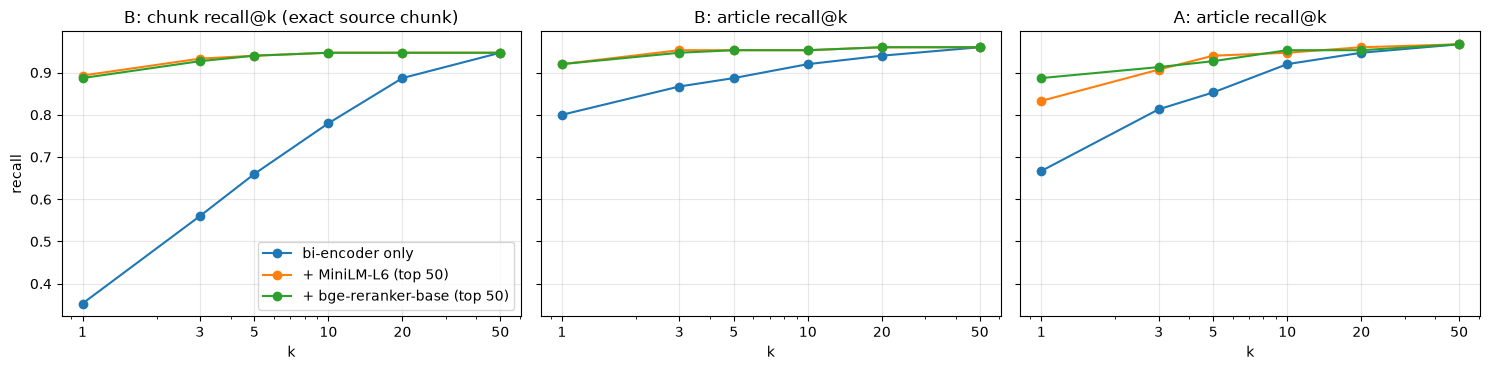

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
panels = [("B", "chunk_recall", "B: chunk recall@k (exact source chunk)"),
          ("B", "doc_recall", "B: article recall@k"),
          ("A", "doc_recall", "A: article recall@k")]
for ax, (s, metric, title) in zip(axes, panels):
    for pipeline in pr_at_k.loc[s].index.get_level_values("pipeline").unique():
        ax.plot(KS, pr_at_k.loc[(s, pipeline, metric)].values, marker="o", label=pipeline)
    ax.set_xscale("log")
    ax.set_xticks(KS, [str(k) for k in KS])
    ax.set_title(title)
    ax.set_xlabel("k")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("recall")
axes[0].legend()
plt.tight_layout()
plt.show()

In [25]:
# Example queries on clean B: bi-encoder order vs cross-encoder order (+ cap 2 applied after reranking)
demo_cands = fetch(clean_cols["B"], demo_embs)
demo_reranked = rerank(rerankers["bge-reranker-base"], DEMO_QUERIES, demo_cands)


def ranked_rows(lists: list[list[dict]], label: str, policy: dict) -> list[dict]:
    rows = []
    for q, cands in zip(DEMO_QUERIES, lists):
        for rank, c in enumerate(select(cands, **policy), 1):
            rows.append(dict(query=q[:40], setup=label, rank=rank, bi_sim=round(c["sim"], 3),
                             ce_score=round(c["ce"], 3) if "ce" in c else None, title=c["title"][:45],
                             chunk_type=c["chunk_type"], text=c["text"][:110].replace("\n", " ")))
    return rows


demo_exp3 = pd.DataFrame(
    ranked_rows(demo_cands, "B clean bi-encoder top-5", {})
    + ranked_rows(demo_reranked, "B clean + bge rerank top-5", {})
    + ranked_rows(demo_reranked, "B clean + bge rerank, cap 2", {"per_doc_cap": 2})
).sort_values(["query", "setup", "rank"], kind="stable")
demo_exp3

,query,setup,rank,bi_sim,ce_score,title,chunk_type,text
25,How do managed futures perform in bear m,B clean + bge rerank top-5,1,0.786,0.999,Why Managed Futures might be the Bear Market,faq,"What are managed futures, in plain English? Managed futures are professionally run strategies that trade futur"
26,How do managed futures perform in bear m,B clean + bge rerank top-5,2,0.768,0.999,Why Managed Futures might be the Bear Market,body,The purpose of this article is simple: to show how managed futures offer a strategic defense in bear markets.
27,How do managed futures perform in bear m,B clean + bge rerank top-5,3,0.761,0.998,Why Managed Futures might be the Bear Market,faq,Why do they tend to help specifically in bear markets? Many managed-futures programs use rules-based trend fol
28,How do managed futures perform in bear m,B clean + bge rerank top-5,4,0.816,0.998,Why Managed Futures might be the Bear Market,body,Managed futures can offer a defensive strategy for those looking to add stability during turbulent markets. Th
29,How do managed futures perform in bear m,B clean + bge rerank top-5,5,0.781,0.998,Why Managed Futures might be the Bear Market,body,"Implementing managed futures can be a smart move, especially for investors seeking a hedge against market down"
40,How do managed futures perform in bear m,"B clean + bge rerank, cap 2",1,0.786,0.999,Why Managed Futures might be the Bear Market,faq,"What are managed futures, in plain English? Managed futures are professionally run strategies that trade futur"
41,How do managed futures perform in bear m,"B clean + bge rerank, cap 2",2,0.768,0.999,Why Managed Futures might be the Bear Market,body,The purpose of this article is simple: to show how managed futures offer a strategic defense in bear markets.
42,How do managed futures perform in bear m,"B clean + bge rerank, cap 2",3,0.708,0.997,How Managed Futures Help Investors Profit Dur,body,The primary aim here is to explore how managed futures provide unique value even during bull markets. We’ll di
43,How do managed futures perform in bear m,"B clean + bge rerank, cap 2",4,0.754,0.983,10 Things Investors Need To Know About Manage,faq,"3) Are managed futures only for bear markets? No. While they’re famous for cushioning crashes, they can also d"
44,How do managed futures perform in bear m,"B clean + bge rerank, cap 2",5,0.683,0.976,How Managed Futures Help Investors Profit Dur,body,"Bull markets capture attention and drive excitement. As prices rise steadily, investor optimism grows, creatin"


In [26]:
exp3.reset_index().to_csv(f"{DATA_DIR}/expt2_exp3_rerank_metrics.csv", index=False)
demo_exp3.to_csv(f"{DATA_DIR}/expt2_exp3_demo_queries.csv", index=False)
print("saved: expt2_exp3_rerank_metrics.csv, expt2_exp3_demo_queries.csv")

saved: expt2_exp3_rerank_metrics.csv, expt2_exp3_demo_queries.csv


### Experiment 3 findings

**Strategy B (clean), bi-encoder only → + cross-encoder (rerank depth 50), top-5 selection:**

| Pipeline | doc_hit@1 | doc_hit@5 | MRR | src_chunk@1 | src_chunk@5 | ms / query |
|---|---|---|---|---|---|---|
| bi-encoder only | 0.800 | 0.887 | 0.841 | 0.353 | 0.660 | n/a |
| + MiniLM-L6 (top 50) | 0.800 → **0.920** | 0.887 → **0.953** | 0.841 → **0.936** | 0.353 → **0.893** | 0.660 → **0.940** | 113 |
| + bge-reranker-base (top 50) | 0.800 → **0.920** | 0.887 → **0.953** | 0.841 → 0.933 | 0.353 → 0.887 | 0.660 → **0.940** | 701 |

**Against the Experiment 2 winner (B clean, bi-encoder + MMR λ=0.6 + cap 2):** both sides apply a per-article cap of 2, so this compares like with like.

| Pipeline (B clean) | doc_hit@1 | doc_hit@5 | MRR | unique_docs@5 | src_chunk@1 | src_chunk@5 | results_returned |
|---|---|---|---|---|---|---|---|
| Expt 2 winner: bi-encoder + MMR λ=0.6 + cap 2 | 0.800 | 0.927 | 0.848 | 3.813 | 0.353 | 0.513 | 4.787 |
| + MiniLM-L6 (top 50) + cap 2 | 0.800 → **0.920** | 0.927 → **0.953** | 0.848 → **0.936** | 3.813 → 3.267 | 0.353 → **0.893** | 0.513 → **0.927** | 4.787 → 4.787 |
| + bge-reranker-base (top 50) + cap 2 | 0.800 → **0.920** | 0.927 → **0.953** | 0.848 → 0.933 | 3.813 → 3.353 | 0.353 → 0.887 | 0.513 → **0.927** | 4.787 → 4.787 |

- Reranking beats the Experiment 2 winner on every relevance metric: +18 questions with the right article first (0.800 → 0.920), +4 with it in the top 5 (0.927 → 0.953), and the exact source chunk ranked first 0.353 → 0.893.
- `unique_docs@5` values vary by up to ±0.015 between runs (ChromaDB's approximate search; see the Experiment 2 findings).
- **The trade-off is variety.** MMR spreads results across more articles (3.813 vs 3.267–3.353), because it explicitly penalises similar chunks while the cap only limits repeats. For consistency auditing, where cross-article coverage matters most, a follow-up is to combine the two: rerank first, then apply MMR on the **reranker** scores (rescaled to 0–1) instead of the cosine.

**Strategy A (clean), same comparison:**

| Pipeline | doc_hit@1 | doc_hit@5 | MRR | ms / query |
|---|---|---|---|---|
| bi-encoder only | 0.667 | 0.853 | 0.747 | n/a |
| + MiniLM-L6 (top 50) | 0.667 → 0.833 | 0.853 → **0.940** | 0.747 → 0.877 | 178 |
| + bge-reranker-base (top 50) | 0.667 → **0.887** | 0.853 → 0.927 | 0.747 → **0.903** | 1,258 |

- **The cross-encoder is the biggest gain so far.** For B, `doc_hit@1` 0.800 → 0.920 is 18 more questions out of 150 with the right article first. That's well beyond the +3 questions from cleaning (Experiment 2) or the zero change from capping (Experiment 1). For A it's 0.667 → 0.887 (+33 questions).
- **The biggest change is at the chunk level.** `src_chunk@1` 0.353 → 0.893: the bi-encoder often found the right article but put a different chunk from it first, and the cross-encoder fixes that. Caveat: the source FAQ chunk contains the question text word for word, and cross-encoders are very good at spotting that overlap, so this metric is the most inflated one.
- **Rerank depth matters.** Depth 50 beats depth 20 for B (`doc_hit@1` 0.893 → 0.920) at about 2.6× the cost. With depth 20, a cap also returns fewer results (3.63 per query under `cap 2`), because there are fewer candidates left after reranking.
- **Which model:**
  - On B (structured chunks), MiniLM-L6 matches bge-reranker-base (0.920 / 0.953 for both) at about **6× lower latency** (113 vs 701 ms/query).
  - On A (fixed windows), bge is better at `doc_hit@1` (0.887 vs 0.833).
  - With B, the small model is enough.
- **Capping after reranking is free.** With depth 50, `cap 2` raises `unique_docs@5` from 1.960 to 3.267 (MiniLM) with **no** change in `doc_hit@1/@5` or MRR. Compare Experiment 1, where capping the bi-encoder order could push out the answer.
- **The GDE case is fixed.** The chunk saying "expense ratio around 0.20%" moves from bi-encoder rank 3 (sim 0.574, tied with 2 others) to **#1** with a bge score of 0.989. The next articles score ≤ 0.125.
- **Cross-encoder scores are usable as a relevance threshold; bi-encoder similarities weren't.** bge outputs probabilities, and off-topic chunks get ≤ 0.13 while answers get > 0.95. That supports a "not enough evidence" cutoff (e.g. drop results below 0.5), which a fixed cosine cutoff couldn't do (the correct GDE chunk had cosine 0.574 and off-topic chunks had 0.51–0.53).

**Precision@k / recall@k** (full ranked lists of 50, before any cap; bi-encoder → + MiniLM-L6 rerank):

| Strategy B (clean) | @1 | @3 | @5 | @10 | @20 | @50 |
|---|---|---|---|---|---|---|
| chunk_recall | 0.353 → **0.893** | 0.560 → **0.933** | 0.660 → **0.940** | 0.780 → **0.947** | 0.887 → 0.947 | 0.947 → 0.947 |
| chunk_precision | 0.353 → **0.893** | 0.187 → **0.311** | 0.132 → **0.188** | 0.078 → **0.095** | 0.044 → 0.047 | 0.019 → 0.019 |
| doc_recall | 0.800 → **0.920** | 0.867 → **0.953** | 0.887 → **0.953** | 0.920 → **0.953** | 0.940 → 0.960 | 0.960 → 0.960 |
| doc_precision | 0.800 → **0.920** | 0.764 → 0.756 | 0.761 → 0.724 | 0.741 → 0.709 | 0.706 → 0.709 | 0.522 → 0.522 |

| Strategy A (clean) | @1 | @3 | @5 | @10 | @20 | @50 |
|---|---|---|---|---|---|---|
| doc_recall | 0.667 → **0.833** | 0.813 → **0.907** | 0.853 → **0.940** | 0.920 → **0.947** | 0.947 → 0.960 | 0.967 → 0.967 |
| doc_precision | 0.667 → **0.833** | 0.653 → **0.744** | 0.627 → **0.721** | 0.561 → **0.660** | 0.438 → **0.514** | 0.231 → 0.231 |

(bge-reranker-base gives nearly identical recall; its `doc_precision@5` is lower: 0.708 for B, 0.677 for A.)

- **Recall improves most at small k.** The reranked top 3 for B (chunk recall 0.933) beats the bi-encoder's top 20 (0.887). For the LLM, which only sees about 5 chunks, this is the gain that matters.
- **Recall@50 doesn't change and can't** (0.947 chunk / 0.960 article for B). The reranker only reorders the bi-encoder's 50 candidates, so the bi-encoder sets the ceiling. The ~5% of questions whose source chunk isn't in the top 50 need a larger `K_FETCH` or a better first-stage model.
- **Chunk precision just tracks recall.** With one relevant chunk per question, `chunk_precision@k = chunk_recall@k / k`, capped at 1/k.
- **Article precision drops slightly for B at k = 3–10** (@5: 0.761 → 0.724) but rises for A (@5: 0.627 → 0.721). For B, the reranker swaps some same-article chunks for chunks from *other* articles, which this metric counts as wrong even when they're relevant (e.g. three different All Weather articles for the All Weather query). It's a lower bound, and it penalises the cross-article variety the auditor needs. A proper precision measure needs graded labels.

**Updated recommended pipeline:**
```
clean text → Strategy B chunks → mpnet bi-encoder top 50 (Chroma)
→ cross-encoder rerank (MiniLM-L6; bge for fixed-size chunks)
→ drop results with reranker score below a threshold → cap 2–3 per article → top 5 to the LLM
```

**Caveat:** every number here uses FAQ-derived questions that appear almost word for word in the index. Before choosing a threshold or a model for production, build a harder evaluation set: reworded claims, claims with altered numbers, and claims about things the corpus never mentions.